# Kit & Crest Studio
### Final prototype · choose, preview, export, reopen

Create a team identity with procedural shapes. The notebook supplies controls; **`drawing.py` contains the commented drawing code**. Run all cells in order from this project folder. This initial run displays the demo without overwriting files. Only **Save artwork + preset** writes the current design.

The same drawings can be exported without Jupyter using `python render_design.py`. Scores and clock text are fictional manual values, not a live scoreboard.

In [1]:
from pathlib import Path
from IPython.display import display
from drawing import (read_project, make_crest, make_shirt, make_team_sheet,
                     make_pattern_sheet, make_match_card, save_artwork)

# Starting from a known example.
folder = Path.cwd()
design, match = read_project(folder / "Presets/demo.json")
print("Loaded:", design["team"], "|", design["crest"], "|", design["pattern"])
print("Exports will be saved separately.")

Loaded: River City FC | shield | sash
Exports will be saved separately.


## See the drawing stages
A transparent crest is drawn from a polygon or ellipse, initials and a diamond. A grayscale mask clips the shirt to its outline; its three patterns reuse that outline. A presentation sheet places the resulting PNG assets together. Read `make_crest()` and `make_shirt()` in `drawing.py` alongside these previews.

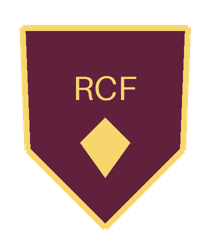

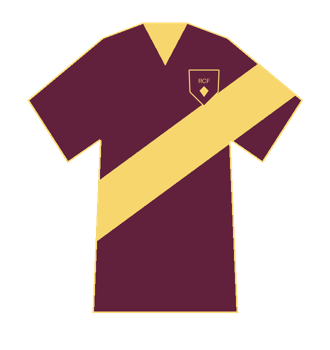

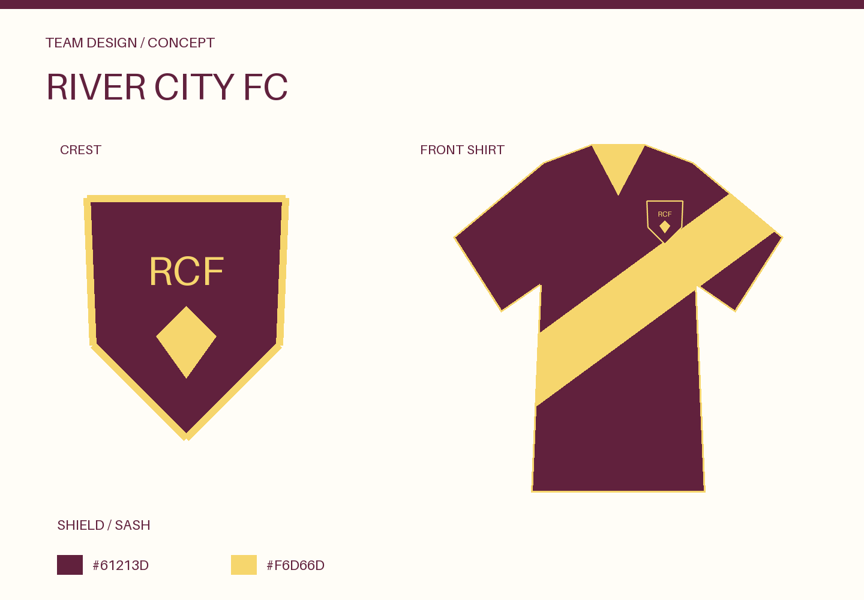

In [2]:
crest = make_crest(design)
shirt = make_shirt(design, crest, design["pattern"])
display(crest.resize((210, 250)))
display(shirt.resize((330, 350)))
display(make_team_sheet(design, crest, shirt).resize((864, 600)))

## Compare and reuse
Only the pattern changes across the three shirts. The match card reuses the same crest and colours. `fit_text()` measures long labels and reduces the font size, then shortens with dots if necessary; full names remain in the saved JSON. SVG export uses vector shapes rather than embedding the PNG.

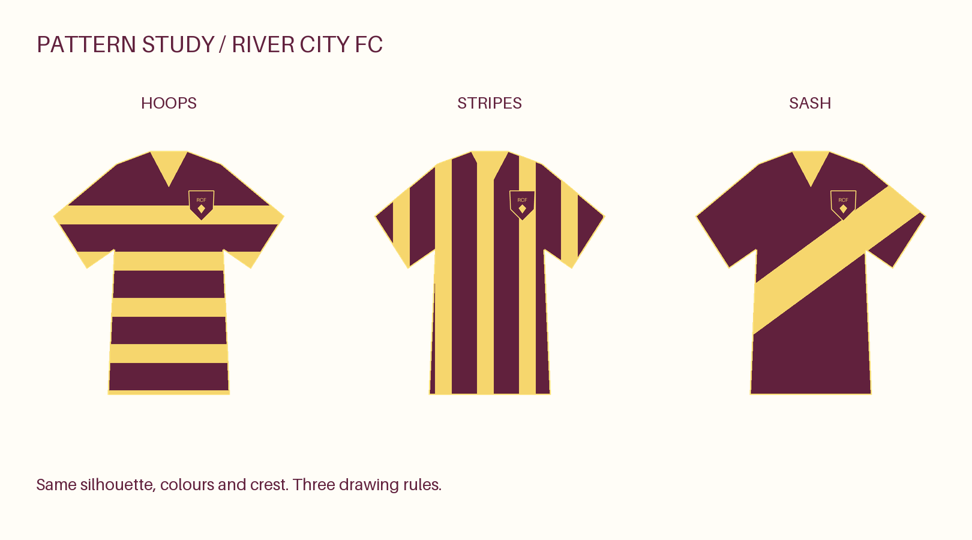

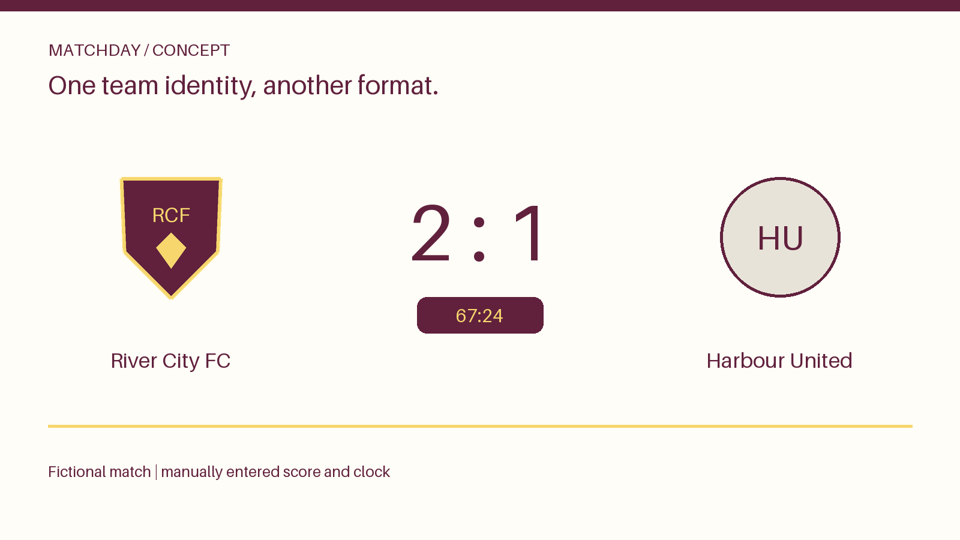

In [3]:
display(make_pattern_sheet(design, crest).resize((972, 540)))
display(make_match_card(design, crest, match).resize((960, 540)))

## Customize Own Version
Change the name, palette, crest, pattern and match information below. Preview changes stay in memory. Save artwork + preset exports the complete set into `Exports/` and saves `Presets/reviewed_team.json`; a later save replaces those files. Copy a preset before saving another version we want to keep.

Choose `alternate.json` and press Load preset to try a round crest and long names. Loading also updates only the controls and preview. The saved `reviewed_team.json` appears in the menu after the first save, and can be loaded again after restarting the notebook.

In [4]:
import io
import json
import ipywidgets as widgets

# Explicit controls make design choices visible without editing drawing coordinates.
team_name = widgets.Text(value=design["team"], description="Team:")
primary = widgets.ColorPicker(value=design["primary"], description="Primary:")
secondary = widgets.ColorPicker(value=design["secondary"], description="Secondary:")
crest_choice = widgets.Dropdown(options=["shield", "round"], value=design["crest"], description="Crest:")
pattern_choice = widgets.Dropdown(options=["hoops", "stripes", "sash"], value=design["pattern"], description="Pattern:")
opponent = widgets.Text(value=match["opponent"], description="Opponent:")
home_score = widgets.BoundedIntText(value=match["home_score"], min=0, max=99, description="Home:")
away_score = widgets.BoundedIntText(value=match["away_score"], min=0, max=99, description="Away:")
clock = widgets.Text(value=match["clock"], description="Clock:")
preset_menu = widgets.Dropdown(options=sorted(path.name for path in (folder / "Presets").glob("*.json")),
                               value="demo.json", description="Preset:")
load_button = widgets.Button(description="Load preset")
save_button = widgets.Button(description="Save artwork + preset", button_style="success",
                             layout=widgets.Layout(width="210px"))
status = widgets.Label()
sheet_preview = widgets.Image(format="png", width=864)
card_preview = widgets.Image(format="png", width=864)
loading = False


def selected_settings():
    # Empty labels get neutral defaults so blank typing does not break a preview.
    new_design = {"team": team_name.value.strip() or "My Team", "primary": primary.value,
                  "secondary": secondary.value, "crest": crest_choice.value, "pattern": pattern_choice.value}
    new_match = {"opponent": opponent.value.strip() or "Opponent", "home_score": home_score.value,
                 "away_score": away_score.value, "clock": clock.value.strip() or "00:00"}
    return new_design, new_match


def png_bytes(image):
    buffer = io.BytesIO()
    image.save(buffer, format="PNG")
    return buffer.getvalue()


def update_preview(change=None):
    if loading:
        return
    new_design, new_match = selected_settings()
    new_crest = make_crest(new_design)
    new_shirt = make_shirt(new_design, new_crest, new_design["pattern"])
    sheet_preview.value = png_bytes(make_team_sheet(new_design, new_crest, new_shirt).resize((864, 600)))
    card_preview.value = png_bytes(make_match_card(new_design, new_crest, new_match).resize((864, 486)))
    status.value = "Preview only. Save when the design is ready."


def save_selected(button):
    new_design, new_match = selected_settings()
    save_artwork(new_design, new_match, folder / "Exports")
    project = {"design": new_design, "match": new_match}
    (folder / "Presets/reviewed_team.json").write_text(json.dumps(project, indent=2), encoding="utf-8")
    preset_menu.options = sorted(path.name for path in (folder / "Presets").glob("*.json"))
    status.value = "Saved complete artwork to Exports/ and preset to Presets/reviewed_team.json."


def load_selected(button):
    global loading
    new_design, new_match = read_project(folder / "Presets" / preset_menu.value)
    # Suppress intermediate redraws while several controls are being filled.
    loading = True
    team_name.value = new_design["team"]
    primary.value, secondary.value = new_design["primary"], new_design["secondary"]
    crest_choice.value, pattern_choice.value = new_design["crest"], new_design["pattern"]
    opponent.value, clock.value = new_match["opponent"], new_match["clock"]
    home_score.value, away_score.value = new_match["home_score"], new_match["away_score"]
    loading = False
    update_preview()
    status.value = "Loaded preset into preview. Exported files have not changed."


controls = [team_name, primary, secondary, crest_choice, pattern_choice, opponent, home_score, away_score, clock]
for control in controls:
    control.observe(update_preview, names="value")
save_button.on_click(save_selected)
load_button.on_click(load_selected)
update_preview()
display(widgets.VBox([widgets.HBox([preset_menu, load_button]), team_name,
                      widgets.HBox([primary, secondary]), widgets.HBox([crest_choice, pattern_choice]),
                      opponent, widgets.HBox([home_score, away_score]), clock,
                      sheet_preview, card_preview, save_button, status]))